<a href="https://colab.research.google.com/github/sahferr/ciencia-da-computacao/blob/main/analise_regularidade_c_endotelial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
Path('/content/drive/MyDrive/endotelio').mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [2]:
import sys, importlib
sys.path.append('/content/drive/MyDrive/endotelio')
import funcoes
importlib.reload(funcoes)
from funcoes import *

In [3]:
import math
from skimage.segmentation import watershed
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

LIMIAR = 0.3        # confiança mínima para virar centro
RAIO_ACERTO = 5     # px para contar como acerto
PESO_MAPA = 0.5     # 0 = bordas pela imagem | 1 = pelo mapa da U-Net
TOLERANCIA = 0.10   # fórmula do professor
HEX_MIN = 60        # referência clínica (%)
CV_MAX = 0.30       # referência clínica

In [4]:
modelo = carregar_modelo()
teste = listar_conjunto(DATASET / 'test')
print(f'Modelo carregado | Exames de teste: {len(teste)}')

Modelo carregado | Exames de teste: 116


In [5]:
def dentro_da_mascara(pontos, mascara):
    return pontos[mascara[pontos[:, 0], pontos[:, 1]] > 0]

In [6]:
def casar_pontos(pred, real, raio=RAIO_ACERTO):
    if len(pred) == 0 or len(real) == 0:
        return 0, len(pred), len(real)
    dist = cdist(pred, real)
    lin, col = linear_sum_assignment(dist)
    vp = int((dist[lin, col] <= raio).sum())
    return vp, len(pred) - vp, len(real) - vp

In [7]:
def avaliar_imagem(modelo, img_path, txt_path):
    img = carregar_cinza(img_path)
    centros = ler_centros(txt_path)
    real = centros[['y', 'x']].to_numpy()
    pred = dentro_da_mascara(achar_centros(prever_mapa(modelo, img), LIMIAR),
                             gerar_mascara(img.shape, centros))
    vp, fp, fn = casar_pontos(pred, real)
    return {'imagem': img_path.name, 'reais': len(real), 'previstas': len(pred),
            'vp': vp, 'fp': fp, 'fn': fn}

In [8]:
def metricas(df):
    vp, fp, fn = df[['vp', 'fp', 'fn']].sum()
    precisao = vp / max(vp + fp, 1)
    recall = vp / max(vp + fn, 1)
    f1 = 2 * precisao * recall / max(precisao + recall, 1e-9)
    validas = df[df['reais'] > 0]
    erro = 100 * ((validas['previstas'] - validas['reais']).abs() / validas['reais']).mean()
    return {'precisao': round(precisao, 3), 'recall': round(recall, 3),
            'f1': round(f1, 3), 'erro_contagem_%': round(erro, 1)}

In [9]:
def visualizar_reconhecimento(modelo, img_path, txt_path):
    img = carregar_cinza(img_path)
    centros = ler_centros(txt_path)
    mapa = prever_mapa(modelo, img)
    pred = dentro_da_mascara(achar_centros(mapa, LIMIAR), gerar_mascara(img.shape, centros))
    vis = desenhar_pontos(img, centros['x'], centros['y'], cor=(0, 255, 0))
    for y, x in pred:
        cv2.circle(vis, (int(x), int(y)), 2, (255, 0, 0), -1)
    mostrar_etapas({'Mapa previsto': mapa, 'Verde = real | Vermelho = previsto': vis})

Métricas: {'precisao': 0.761, 'recall': 0.875, 'f1': 0.814, 'erro_contagem_%': np.float64(26.9)}


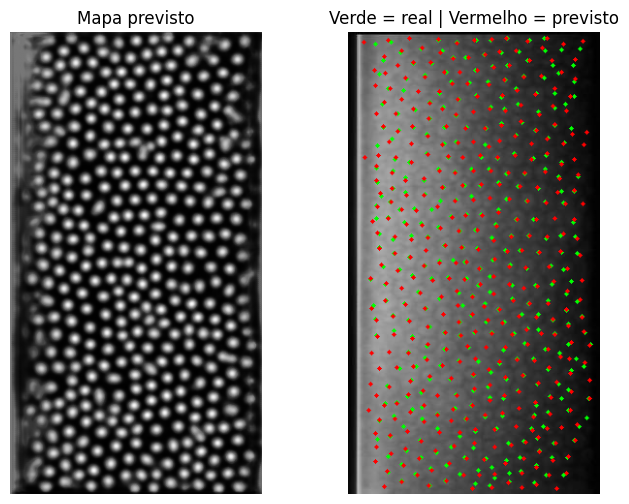

In [10]:
reconhecimento = pd.DataFrame([avaliar_imagem(modelo, i, t) for i, t in teste])
reconhecimento.to_csv(PASTA_DRIVE / 'reconhecimento.csv', index=False)
print('Métricas:', metricas(reconhecimento))

idx = reconhecimento['reais'].idxmax()
visualizar_reconhecimento(modelo, *teste[idx])

In [11]:
def segmentar_celulas(img, mapa, centros_pred, peso_mapa=PESO_MAPA, sigma=1.5, margem=10):
    suave = cv2.GaussianBlur(corrigir_iluminacao(img), (0, 0), sigma).astype(np.float32) / 255
    relevo = -(peso_mapa * mapa + (1 - peso_mapa) * suave)
    marcadores = np.zeros(img.shape, np.int32)
    marcadores[centros_pred[:, 0], centros_pred[:, 1]] = np.arange(1, len(centros_pred) + 1)
    pontos = pd.DataFrame({'x': centros_pred[:, 1], 'y': centros_pred[:, 0]})
    roi = gerar_mascara(img.shape, pontos, margem)
    rot = watershed(relevo, marcadores, mask=roi.astype(bool), watershed_line=True)
    return rot, roi

In [12]:
def remover_tocando_roi(rot, roi):
    fora = (roi == 0).astype(np.uint8)
    fora[[0, -1], :] = 1
    fora[:, [0, -1]] = 1
    contato = cv2.dilate(fora, np.ones((3, 3), np.uint8)) > 0
    rot = rot.copy()
    rot[np.isin(rot, np.unique(rot[contato]))] = 0
    return rot

In [13]:
def filtrar_por_area(rot, area_min=30, area_max=2000):
    areas = np.bincount(rot.ravel())
    validos = np.where((areas >= area_min) & (areas <= area_max))[0]
    validos = validos[validos > 0]
    return np.where(np.isin(rot, validos), rot, 0)

In [14]:
def extrair_contorno(mask):
    cs, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return max(cs, key=cv2.contourArea)

In [15]:
def contar_vizinhos(rot_completo, i):
    mask = (rot_completo == i).astype(np.uint8)
    anel = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=2) - mask
    vizinhos = np.unique(rot_completo[anel > 0])
    return int(np.sum((vizinhos > 0) & (vizinhos != i)))

In [16]:
def medir_circulos(mask, contorno):
    r_in = cv2.distanceTransform(mask, cv2.DIST_L2, 5).max()
    _, r_out = cv2.minEnclosingCircle(contorno)
    return float(r_in), float(r_out)

In [17]:
COLUNAS_CELULA = ['id', 'area', 'lados', 'r_in', 'r_out']

def medir_celulas(rot, rot_completo):
    linhas, contornos = [], []
    for i in np.unique(rot):
        if i == 0:
            continue
        mask = (rot == i).astype(np.uint8)
        contorno = extrair_contorno(mask)
        r_in, r_out = medir_circulos(mask, contorno)
        linhas.append({'id': int(i), 'area': int(mask.sum()),
                       'lados': contar_vizinhos(rot_completo, i),
                       'r_in': r_in, 'r_out': r_out})
        contornos.append(contorno)
    return pd.DataFrame(linhas, columns=COLUNAS_CELULA), contornos

In [18]:
def indice_hexagonal(r_in, r_out):
    return (r_in / r_out) / math.cos(math.pi / 6)

In [19]:
def classificar(df, tolerancia=TOLERANCIA):
    df = df.copy()
    df['indice'] = [indice_hexagonal(a, b) for a, b in zip(df['r_in'], df['r_out'])]
    df['regular'] = (df['indice'] - 1).abs() <= tolerancia
    df['grupo'] = np.where(df['regular'], 'regular', 'irregular')
    return df

In [20]:
def avaliar_exame(df, rot_completo):
    regulares = int(df['regular'].sum())
    irregulares = len(df) - regulares
    hex_pct = 100 * (df['lados'] == 6).mean() if len(df) else 0.0
    cv = df['area'].std() / df['area'].mean() if len(df) > 1 else 0.0
    return {'total_aprox': len(np.unique(rot_completo)) - 1, 'analisadas': len(df),
            'regulares': regulares, 'irregulares': irregulares,
            'irregular_acima_regular': irregulares > regulares,
            'hex_%': round(hex_pct, 1), 'cv': round(cv, 3),
            'pleomorfismo': hex_pct < HEX_MIN, 'polimegatismo': cv > CV_MAX}

In [21]:
def desenhar_classificacao(img, contornos, df):
    cor = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for contorno, regular in zip(contornos, df['regular']):
        cv2.drawContours(cor, [contorno], -1, (0, 255, 0) if regular else (255, 0, 0), 1)
    return cor

In [22]:
def analisar_exame(modelo, img_path, peso_mapa=PESO_MAPA):
    img = carregar_cinza(img_path)
    mapa = prever_mapa(modelo, img)
    centros_pred = achar_centros(mapa, LIMIAR)
    rot_completo, roi = segmentar_celulas(img, mapa, centros_pred, peso_mapa)
    rot = filtrar_por_area(remover_tocando_roi(rot_completo, roi))
    celulas, contornos = medir_celulas(rot, rot_completo)
    celulas = classificar(celulas)
    return img, celulas, contornos, avaliar_exame(celulas, rot_completo)

In [23]:
def resumo_grupos(celulas):
    return celulas.groupby('grupo').agg(
        quantidade=('id', 'count'),
        area_media=('area', 'mean'),
        indice_medio=('indice', 'mean'),
    ).round(2)

peso_mapa=0 | HEX 35.5% | CV 0.547 | regulares 52 | irregulares 210


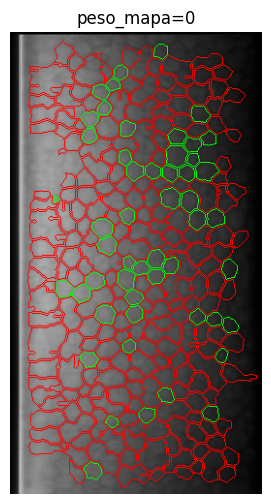

peso_mapa=0.5 | HEX 56.1% | CV 0.205 | regulares 177 | irregulares 178


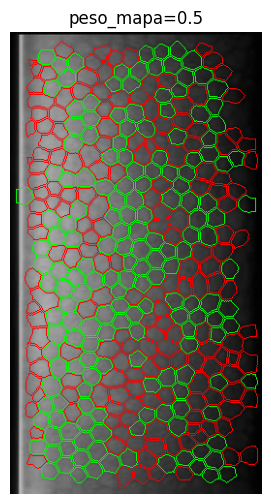

peso_mapa=1 | HEX 56.2% | CV 0.205 | regulares 201 | irregulares 167


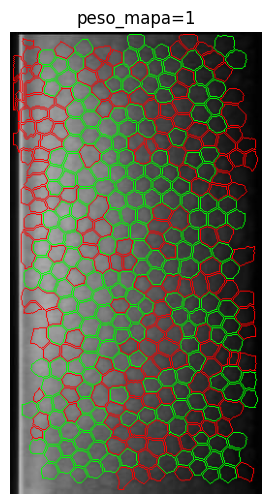

In [24]:
for peso in (0, 0.5, 1):
    img, celulas, contornos, resumo = analisar_exame(modelo, teste[idx][0], peso_mapa=peso)
    print(f"peso_mapa={peso} | HEX {resumo['hex_%']}% | CV {resumo['cv']} | "
          f"regulares {resumo['regulares']} | irregulares {resumo['irregulares']}")
    mostrar_etapas({f'peso_mapa={peso}': desenhar_classificacao(img, contornos, celulas)})

Células identificadas: 406 | analisadas: 355
HEX: 56.1% | CV: 0.205 | Irregular > regular: True


,quantidade,area_media,indice_medio
grupo,,,
irregular,178,250.49,0.83
regular,177,245.12,0.95


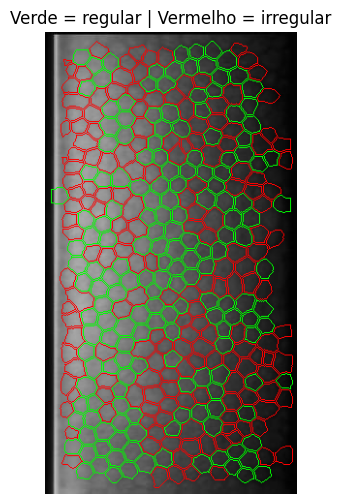

In [25]:
img, celulas, contornos, resumo = analisar_exame(modelo, teste[idx][0])

print(f"Células identificadas: {resumo['total_aprox']} | analisadas: {resumo['analisadas']}")
print(f"HEX: {resumo['hex_%']}% | CV: {resumo['cv']} | Irregular > regular: {resumo['irregular_acima_regular']}")
display(resumo_grupos(celulas))
mostrar_etapas({'Verde = regular | Vermelho = irregular': desenhar_classificacao(img, contornos, celulas)})

In [26]:
def relatorio_conjunto(modelo, pares):
    todas, exames = [], []
    for img_path, _ in pares:
        _, celulas, _, resumo = analisar_exame(modelo, img_path)
        celulas.insert(0, 'imagem', img_path.name)
        todas.append(celulas)
        exames.append({'imagem': img_path.name, **resumo})
    return pd.concat(todas, ignore_index=True), pd.DataFrame(exames)

In [27]:
celulas_todas, exames = relatorio_conjunto(modelo, teste)
celulas_todas.to_csv(PASTA_DRIVE / 'celulas.csv', index=False)
exames.to_csv(PASTA_DRIVE / 'exames.csv', index=False)

print(f'Exames: {len(exames)} | Células: {len(celulas_todas)}')
print(celulas_todas['grupo'].value_counts())
exames.head()

Exames: 116 | Células: 22313
grupo
irregular    17080
regular       5233
Name: count, dtype: int64


,imagem,total_aprox,analisadas,regulares,irregulares,irregular_acima_regular,hex_%,cv,pleomorfismo,polimegatismo
0,71866.tiff,343,287,153,134,False,59.6,0.271,True,False
1,71869.tiff,599,224,18,206,True,34.4,0.643,True,True
2,71871.tiff,349,290,130,160,True,53.4,0.233,True,False
3,71873.tiff,307,171,32,139,True,46.8,0.513,True,True
4,71875.tiff,194,116,32,84,True,59.5,0.383,True,True
